In [ ]:
!pip install -q mlflow==3.18.0 hmmlearn==0.3.3 scikit-learn pandas numpy scipy matplotlib seaborn

In [ ]:
import mlflow
import hmmlearn
import sklearn
import numpy as np
import pandas as pd
import scipy

print("MLflow:", mlflow.__version__)
print("hmmlearn:", hmmlearn.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

print("\nAll libraries imported successfully!")

MLflow: 3.18.0
hmmlearn: 0.3.3
Scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3

All libraries imported successfully!


In [ ]:
data = pd.read_csv("/content/cleaned_ASAG2024_train.csv")
test_data = pd.read_csv("/content/cleaned_ASAG2024_test.csv")

print("Training dataset:", data.shape)
print("External test dataset:", test_data.shape)

display(data.head())

Training dataset: (15153, 11)
External test dataset: (1898, 11)


,question,provided_answer,reference_answer,grade,data_source,normalized_grade,weight,index,answer_word_count,reference_word_count,answer_reference_ratio
0,"Look at the 2 pictures of drops on a flat, wat...",The plain water looks like it does because pla...,Surface tension causes the plain water to look...,0.0,SciEntsBank,0.0,0.000092,4262,24,11,2.181818
1,What is the “Dynamic Host Configuration Protoc...,The Dynamic Host Configuration Protocol (DHCP)...,The Dynamic Host Configuration Protocol (DHCP)...,1.0,SAF,1.0,0.000080,22,81,75,1.080000
2,Why does the level of the water in the straw g...,Because the hotter it is the higher it goes up.,Water expands when water is heated.,0.0,SciEntsBank,0.0,0.000092,2034,10,6,1.666667
3,What requirement has to be met so that you can...,It is a duplex operation so communication has ...,Piggybacking only makes sense if there is a fu...,0.5,SAF,0.5,0.000227,1171,37,27,1.370370
4,Explain in one sentence what each graph tells ...,This graph tells me the number of the tree's r...,"As time increases, the number of tree rings al...",0.0,SciEntsBank,0.0,0.000092,1339,13,10,1.300000


In [ ]:
print("Training columns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

print("\nNormalized grade distribution:")
print(data["normalized_grade"].value_counts().sort_index())

print("\nGrade statistics:")
display(data["normalized_grade"].describe())

Training columns:
['question', 'provided_answer', 'reference_answer', 'grade', 'data_source', 'normalized_grade', 'weight', 'index', 'answer_word_count', 'reference_word_count', 'answer_reference_ratio']

Missing values:
question                  877
provided_answer             0
reference_answer            0
grade                       0
data_source                 0
normalized_grade            0
weight                      0
index                       0
answer_word_count           0
reference_word_count        0
answer_reference_ratio      0
dtype: int64

Normalized grade distribution:
normalized_grade
0.000000    2652
0.090909       1
0.100000       1
0.125000       1
0.200000      35
0.209302       7
0.250000      99
0.295455       1
0.300000      10
0.333333    1678
0.375000       4
0.380000       2
0.395349       8
0.400000      37
0.409091      29
0.488372       3
0.500000     582
0.590909      19
0.600000      10
0.600000      49
0.604651      19
0.625000      16
0.630000     

,normalized_grade
count,15153.000000
mean,0.647158
std,0.375726
min,0.000000
25%,0.333333
50%,0.666667
75%,1.000000
max,1.000000


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Select required columns
prepared_data = data[
    ["provided_answer", "reference_answer", "normalized_grade"]
].copy()

# Clean student answers
prepared_data = prepared_data.dropna(
    subset=["provided_answer", "normalized_grade"]
)

prepared_data["provided_answer"] = (
    prepared_data["provided_answer"].astype(str)
)

prepared_data = prepared_data[
    prepared_data["provided_answer"].str.strip() != ""
].copy()

# Create five grade bands
prepared_data["grade_band"] = np.digitize(
    prepared_data["normalized_grade"],
    bins=[0.2, 0.4, 0.6, 0.8],
    right=True
)

# Stratified train-validation split
train_df, val_df = train_test_split(
    prepared_data,
    test_size=0.20,
    random_state=42,
    stratify=prepared_data["grade_band"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Prepared dataset:", prepared_data.shape)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining grade distribution:")
print(train_df["grade_band"].value_counts().sort_index())

print("\nValidation grade distribution:")
print(val_df["grade_band"].value_counts().sort_index())

print("\nData preparation completed!")

Prepared dataset: (15153, 4)
Training samples: 12122
Validation samples: 3031

Training grade distribution:
grade_band
0    2152
1    1477
2     514
3    2694
4    5285
Name: count, dtype: int64

Validation grade distribution:
grade_band
0     538
1     369
2     129
3     674
4    1321
Name: count, dtype: int64

Data preparation completed!


In [ ]:
import re
from collections import Counter

MAX_VOCAB = 2000
MAX_LENGTH = 120

def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Build vocabulary from training answers only
word_counts = Counter()

for answer in train_df["provided_answer"]:
    word_counts.update(tokenize(answer))

# Reserve ID 0 for unknown words
vocab = {"<UNK>": 0}

for word, count in word_counts.most_common(MAX_VOCAB - 1):
    vocab[word] = len(vocab)

def encode_answer(text):
    tokens = tokenize(text)
    sequence = [vocab.get(token, 0) for token in tokens]

    if not sequence:
        sequence = [0]

    return sequence[:MAX_LENGTH]

# Encode training and validation answers
train_sequences = [
    encode_answer(answer)
    for answer in train_df["provided_answer"]
]

val_sequences = [
    encode_answer(answer)
    for answer in val_df["provided_answer"]
]

print("Vocabulary size:", len(vocab))
print("Maximum sequence length:", MAX_LENGTH)
print("Training sequences:", len(train_sequences))
print("Validation sequences:", len(val_sequences))

print("\nSample token sequence:")
print(train_sequences[0][:20])

print("\nTokenization completed!")

Vocabulary size: 2000
Maximum sequence length: 120
Training sequences: 12122
Validation sequences: 3031

Sample token sequence:
[340, 53, 9, 36, 47, 0, 1256, 184, 53, 247, 7, 15, 498, 10, 83, 23, 33, 276, 15, 12]

Tokenization completed!


In [ ]:
import warnings
from hmmlearn.hmm import CategoricalHMM
from scipy.special import softmax

warnings.filterwarnings("ignore")

N_FEATURES = len(vocab)
GRADE_CENTERS = np.array([0.1, 0.3, 0.5, 0.7, 0.9])

def train_hmm_configuration(
    n_states,
    n_iter,
    prior,
    random_state=42
):
    models = {}

    class_priors = (
        train_df["grade_band"]
        .value_counts(normalize=True)
        .sort_index()
        .values
    )

    for grade in range(5):

        indices = np.where(
            train_df["grade_band"].values == grade
        )[0]

        rng = np.random.default_rng(random_state + grade)
        rng.shuffle(indices)

        indices = indices[:1500]

        sequences = [train_sequences[i] for i in indices]
        lengths = [len(seq) for seq in sequences]

        X = np.concatenate([
            np.asarray(seq, dtype=np.int64)
            for seq in sequences
        ]).reshape(-1, 1)

        model = CategoricalHMM(
            n_components=n_states,
            n_features=N_FEATURES,
            startprob_prior=prior,
            transmat_prior=prior,
            emissionprob_prior=prior,
            n_iter=n_iter,
            tol=0.01,
            random_state=random_state + grade,
            implementation="log",
            verbose=False
        )

        model.fit(X, lengths)

        models[grade] = model

    return models, class_priors


def predict_hmm_configuration(models, class_priors, sequences):

    predicted_bands = []
    predicted_marks = []

    for sequence in sequences:

        X = np.asarray(sequence, dtype=np.int64).reshape(-1, 1)

        scores = np.array([
            models[g].score(X) + np.log(class_priors[g])
            for g in range(5)
        ])

        probabilities = softmax(scores)

        predicted_bands.append(int(np.argmax(probabilities)))

        predicted_marks.append(
            float(np.dot(probabilities, GRADE_CENTERS) * 10)
        )

    return (
        np.array(predicted_bands),
        np.array(predicted_marks)
    )


print("HMM training and prediction functions defined successfully!")

HMM training and prediction functions defined successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    cohen_kappa_score,
    f1_score
)

def evaluate_hmm(y_true, predicted_bands, predicted_marks):

    actual_marks = (
        val_df["normalized_grade"].to_numpy() * 10
    )

    results = {
        "accuracy": accuracy_score(
            y_true, predicted_bands
        ),
        "mae": mean_absolute_error(
            actual_marks, predicted_marks
        ),
        "rmse": np.sqrt(
            mean_squared_error(actual_marks, predicted_marks)
        ),
        "qwk": cohen_kappa_score(
            y_true, predicted_bands, weights="quadratic"
        ),
        "macro_f1": f1_score(
            y_true, predicted_bands,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, predicted_bands,
            average="weighted", zero_division=0
        )
    }

    return results


print("Evaluation function defined successfully!")

Evaluation function defined successfully!


In [ ]:
import os
import mlflow

# New experiment storage
MLFLOW_DB = "/content/hmm_hyperparameter_tuning.db"
ARTIFACT_DIR = "/content/hmm_hyperparameter_artifacts"

os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Configure MLflow
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

experiment_name = "HMM_Hyperparameter_Optimization"

experiment = mlflow.set_experiment(experiment_name)

print("MLflow setup completed!")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", experiment_name)
print("Experiment ID:", experiment.experiment_id)
print("Artifact directory:", ARTIFACT_DIR)

2026/11/15 12:51:00 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/15 12:51:01 INFO mlflow.store.db.utils: Updating database tables
2026/11/15 12:51:04 INFO mlflow.tracking.fluent: Experiment with name 'HMM_Hyperparameter_Optimization' does not exist. Creating a new experiment.


MLflow setup completed!
Tracking URI: sqlite:////content/hmm_hyperparameter_tuning.db
Experiment: HMM_Hyperparameter_Optimization
Experiment ID: 1
Artifact directory: /content/hmm_hyperparameter_artifacts


In [ ]:
from itertools import product

search_space = {
    "n_states": [2, 4, 6],
    "n_iter": [15, 25],
    "prior": [1.1, 2.0]
}

configurations = list(product(
    search_space["n_states"],
    search_space["n_iter"],
    search_space["prior"]
))

print("Total configurations:", len(configurations))
print("\nConfigurations:")

for i, (states, iterations, prior) in enumerate(configurations, 1):
    print(
        f"{i:02d}. Hidden States={states}, "
        f"Iterations={iterations}, Prior={prior}"
    )

Total configurations: 12

Configurations:
01. Hidden States=2, Iterations=15, Prior=1.1
02. Hidden States=2, Iterations=15, Prior=2.0
03. Hidden States=2, Iterations=25, Prior=1.1
04. Hidden States=2, Iterations=25, Prior=2.0
05. Hidden States=4, Iterations=15, Prior=1.1
06. Hidden States=4, Iterations=15, Prior=2.0
07. Hidden States=4, Iterations=25, Prior=1.1
08. Hidden States=4, Iterations=25, Prior=2.0
09. Hidden States=6, Iterations=15, Prior=1.1
10. Hidden States=6, Iterations=15, Prior=2.0
11. Hidden States=6, Iterations=25, Prior=1.1
12. Hidden States=6, Iterations=25, Prior=2.0


In [ ]:
import time
import mlflow
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
mlflow.set_experiment("HMM_Hyperparameter_Optimization")

config_results = []

y_val = val_df["grade_band"].to_numpy()

print("Starting HMM hyperparameter optimization...")
print("=" * 65)

for run_number, (states, iterations, prior) in enumerate(configurations, 1):

    run_name = f"HMM_States{states}_Iter{iterations}_Prior{prior}"

    print(f"\n[{run_number}/12] Running: {run_name}")

    start_time = time.time()

    with mlflow.start_run(run_name=run_name):

        # Log hyperparameters
        mlflow.log_params({
            "n_components": states,
            "n_iter": iterations,
            "smoothing_prior": prior,
            "max_vocab": MAX_VOCAB,
            "max_length": MAX_LENGTH,
            "random_state": 42,
            "grade_bands": 5
        })

        # Train five class-specific HMMs
        models, class_priors = train_hmm_configuration(
            n_states=states,
            n_iter=iterations,
            prior=prior,
            random_state=42
        )

        # Predict validation answers
        predicted_bands, predicted_marks = predict_hmm_configuration(
            models,
            class_priors,
            val_sequences
        )

        # Evaluate configuration
        metrics = evaluate_hmm(
            y_val,
            predicted_bands,
            predicted_marks
        )

        training_time = time.time() - start_time

        # Log validation metrics
        mlflow.log_metrics(metrics)
        mlflow.log_metric("training_seconds", training_time)

        # Log classification report
        report = classification_report(
            y_val,
            predicted_bands,
            labels=[0, 1, 2, 3, 4],
            output_dict=True,
            zero_division=0
        )

        mlflow.log_dict(
            report,
            "classification_report.json"
        )

        # Store results
        result = {
            "run_name": run_name,
            "n_components": states,
            "n_iter": iterations,
            "smoothing_prior": prior,
            **metrics,
            "training_seconds": training_time
        }

        config_results.append(result)

        print(
            f"MAE: {metrics['mae']:.4f} | "
            f"Accuracy: {metrics['accuracy']:.4f} | "
            f"QWK: {metrics['qwk']:.4f} | "
            f"Time: {training_time:.1f}s"
        )

print("\n" + "=" * 65)
print("ALL 12 HMM EXPERIMENTS COMPLETED!")

results_df = pd.DataFrame(config_results)

display(
    results_df.sort_values(
        by=["mae", "qwk"],
        ascending=[True, False]
    ).reset_index(drop=True).round(4)
)

Starting HMM hyperparameter optimization...

[1/12] Running: HMM_States2_Iter15_Prior1.1
MAE: 3.3711 | Accuracy: 0.4147 | QWK: 0.2003 | Time: 33.5s

[2/12] Running: HMM_States2_Iter15_Prior2.0
MAE: 3.3399 | Accuracy: 0.4233 | QWK: 0.2118 | Time: 34.3s

[3/12] Running: HMM_States2_Iter25_Prior1.1
MAE: 3.3212 | Accuracy: 0.4170 | QWK: 0.1994 | Time: 50.0s

[4/12] Running: HMM_States2_Iter25_Prior2.0
MAE: 3.3424 | Accuracy: 0.4180 | QWK: 0.2097 | Time: 49.3s

[5/12] Running: HMM_States4_Iter15_Prior1.1
MAE: 2.8629 | Accuracy: 0.4903 | QWK: 0.3177 | Time: 36.9s

[6/12] Running: HMM_States4_Iter15_Prior2.0
MAE: 2.8347 | Accuracy: 0.4843 | QWK: 0.2807 | Time: 39.8s

[7/12] Running: HMM_States4_Iter25_Prior1.1
MAE: 2.8807 | Accuracy: 0.4820 | QWK: 0.3133 | Time: 56.3s

[8/12] Running: HMM_States4_Iter25_Prior2.0


MAE: 2.8704 | Accuracy: 0.4672 | QWK: 0.2596 | Time: 52.3s

[9/12] Running: HMM_States6_Iter15_Prior1.1
MAE: 3.0757 | Accuracy: 0.4418 | QWK: 0.2481 | Time: 38.7s

[10/12] Running: HMM_States6_Iter15_Prior2.0
MAE: 3.0909 | Accuracy: 0.4352 | QWK: 0.2449 | Time: 38.3s

[11/12] Running: HMM_States6_Iter25_Prior1.1
MAE: 3.0563 | Accuracy: 0.4404 | QWK: 0.2375 | Time: 60.4s

[12/12] Running: HMM_States6_Iter25_Prior2.0
MAE: 3.0244 | Accuracy: 0.4480 | QWK: 0.2498 | Time: 60.2s

ALL 12 HMM EXPERIMENTS COMPLETED!


,run_name,n_components,n_iter,smoothing_prior,accuracy,mae,rmse,qwk,macro_f1,weighted_f1,training_seconds
0,HMM_States4_Iter15_Prior2.0,4,15,2.0,0.4843,2.8347,3.5779,0.2807,0.4422,0.4725,39.8303
1,HMM_States4_Iter15_Prior1.1,4,15,1.1,0.4903,2.8629,3.6613,0.3177,0.4523,0.4851,36.8955
2,HMM_States4_Iter25_Prior2.0,4,25,2.0,0.4672,2.8704,3.6091,0.2596,0.4327,0.4633,52.2640
3,HMM_States4_Iter25_Prior1.1,4,25,1.1,0.4820,2.8807,3.6776,0.3133,0.4530,0.4804,56.3188
4,HMM_States6_Iter25_Prior2.0,6,25,2.0,0.4480,3.0244,3.7871,0.2498,0.4304,0.4524,60.2473
5,HMM_States6_Iter25_Prior1.1,6,25,1.1,0.4404,3.0563,3.8548,0.2375,0.4301,0.4483,60.4183
6,HMM_States6_Iter15_Prior1.1,6,15,1.1,0.4418,3.0757,3.8827,0.2481,0.4307,0.4487,38.6560
7,HMM_States6_Iter15_Prior2.0,6,15,2.0,0.4352,3.0909,3.8732,0.2449,0.4245,0.4381,38.3185
8,HMM_States2_Iter25_Prior1.1,2,25,1.1,0.4170,3.3212,4.1418,0.1994,0.4209,0.4149,49.9516
9,HMM_States2_Iter15_Prior2.0,2,15,2.0,0.4233,3.3399,4.1255,0.2118,0.4279,0.4221,34.2909


In [ ]:
import json
import os
import mlflow
import pandas as pd
from mlflow.tracking import MlflowClient

# Rank configurations
ranked_results = results_df.sort_values(
    by=["mae", "qwk"],
    ascending=[True, False]
).reset_index(drop=True)

best_result = ranked_results.iloc[0]

# Find the winning MLflow run
client = MlflowClient()

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="",
    max_results=100
)

best_run = next(
    run for run in runs
    if run.data.tags.get("mlflow.runName") == best_result["run_name"]
)

# Mark the winning configuration
client.set_tag(best_run.info.run_id, "BEST_HMM_CONFIG", "true")
client.set_tag(best_run.info.run_id, "selection_metric", "validation_mae")

# Save comparison results
comparison_path = "/content/hmm_hyperparameter_comparison.csv"
ranked_results.to_csv(comparison_path, index=False)

# Save best configuration
best_config = {
    "run_id": best_run.info.run_id,
    "run_name": best_result["run_name"],
    "n_components": int(best_result["n_components"]),
    "n_iter": int(best_result["n_iter"]),
    "smoothing_prior": float(best_result["smoothing_prior"]),
    "validation_mae": float(best_result["mae"]),
    "validation_accuracy": float(best_result["accuracy"]),
    "validation_qwk": float(best_result["qwk"]),
    "selection_criterion": "Lowest validation MAE; QWK as tie-breaker"
}

best_config_path = "/content/best_hmm_configuration.json"

with open(best_config_path, "w") as f:
    json.dump(best_config, f, indent=4)

# Attach files to winning run
client.log_artifact(
    best_run.info.run_id,
    comparison_path,
    artifact_path="hyperparameter_analysis"
)

client.log_artifact(
    best_run.info.run_id,
    best_config_path,
    artifact_path="hyperparameter_analysis"
)

print("BEST CONFIGURATION MARKED IN MLFLOW")
print("Run ID:", best_run.info.run_id)
print("\nWinning hyperparameters:")
print(json.dumps(best_config, indent=4))

BEST CONFIGURATION MARKED IN MLFLOW
Run ID: 158208d374534fb4b284549b93be2707

Winning hyperparameters:
{
    "run_id": "158208d374534fb4b284549b93be2707",
    "run_name": "HMM_States4_Iter15_Prior2.0",
    "n_components": 4,
    "n_iter": 15,
    "smoothing_prior": 2.0,
    "validation_mae": 2.834656672478366,
    "validation_accuracy": 0.4843286044209832,
    "validation_qwk": 0.2806730500334539,
    "selection_criterion": "Lowest validation MAE; QWK as tie-breaker"
}


In [ ]:
import time
import numpy as np
import mlflow
import joblib
import os

# Prepare all 15,153 training records
final_train_df = prepared_data.reset_index(drop=True)

final_train_sequences = [
    encode_answer(answer)
    for answer in final_train_df["provided_answer"]
]

final_y = final_train_df["grade_band"].to_numpy()

# Selected hyperparameters
BEST_STATES = 4
BEST_ITERATIONS = 15
BEST_PRIOR = 2.0

final_models = {}
final_class_priors = (
    final_train_df["grade_band"]
    .value_counts(normalize=True)
    .sort_index()
    .values
)

print("Training final HMM models...")
start_time = time.time()

for grade in range(5):

    indices = np.where(final_y == grade)[0]

    sequences = [final_train_sequences[i] for i in indices]
    lengths = [len(seq) for seq in sequences]

    X = np.concatenate([
        np.asarray(seq, dtype=np.int64)
        for seq in sequences
    ]).reshape(-1, 1)

    model = CategoricalHMM(
        n_components=BEST_STATES,
        n_features=N_FEATURES,
        startprob_prior=BEST_PRIOR,
        transmat_prior=BEST_PRIOR,
        emissionprob_prior=BEST_PRIOR,
        n_iter=BEST_ITERATIONS,
        tol=0.01,
        random_state=42 + grade,
        implementation="log",
        verbose=False
    )

    model.fit(X, lengths)
    final_models[grade] = model

    print(f"Grade band {grade}: trained on {len(indices)} answers")

training_time = time.time() - start_time

# Save final trained model
final_model_path = "/content/best_hmm_model.joblib"

joblib.dump({
    "models": final_models,
    "class_priors": final_class_priors,
    "vocab": vocab,
    "max_length": MAX_LENGTH,
    "grade_centers": GRADE_CENTERS,
    "hyperparameters": {
        "n_components": BEST_STATES,
        "n_iter": BEST_ITERATIONS,
        "smoothing_prior": BEST_PRIOR
    }
}, final_model_path)

print("\nFINAL HMM TRAINING COMPLETED")
print("Training records:", len(final_train_df))
print("Training time:", round(training_time, 2), "seconds")
print("Model saved:", final_model_path)

# Log final model artifact in a separate MLflow run
with mlflow.start_run(run_name="Final_HMM_Best_Configuration"):

    mlflow.log_params({
        "n_components": BEST_STATES,
        "n_iter": BEST_ITERATIONS,
        "smoothing_prior": BEST_PRIOR,
        "training_records": len(final_train_df),
        "random_state": 42
    })

    mlflow.log_metric("training_seconds", training_time)

    mlflow.set_tag("model_role", "Final selected HMM")
    mlflow.set_tag("selected_from_run", best_run.info.run_id)

    mlflow.log_artifact(
        final_model_path,
        artifact_path="final_model"
    )

    final_run_id = mlflow.active_run().info.run_id

print("Final model MLflow Run ID:", final_run_id)

Training final HMM models...
Grade band 0: trained on 2690 answers
Grade band 1: trained on 1846 answers
Grade band 2: trained on 643 answers
Grade band 3: trained on 3368 answers
Grade band 4: trained on 6606 answers

FINAL HMM TRAINING COMPLETED
Training records: 15153
Training time: 71.68 seconds
Model saved: /content/best_hmm_model.joblib
Final model MLflow Run ID: 908b9846e02d4f1aa4f94ed3d9dfdb40


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    cohen_kappa_score,
    f1_score,
    classification_report
)

# Prepare external test answers
external_test_data = test_data[
    ["provided_answer", "normalized_grade"]
].copy()

external_test_data = external_test_data.dropna(
    subset=["provided_answer", "normalized_grade"]
)

external_test_data["provided_answer"] = (
    external_test_data["provided_answer"].astype(str)
)

external_test_data = external_test_data[
    external_test_data["provided_answer"].str.strip() != ""
].reset_index(drop=True)

# Encode using the original training vocabulary
external_sequences = [
    encode_answer(answer)
    for answer in external_test_data["provided_answer"]
]

# Actual grades
actual_marks = (
    external_test_data["normalized_grade"].to_numpy() * 10
)

actual_bands = np.digitize(
    actual_marks,
    bins=[2, 4, 6, 8],
    right=True
)

# Predict using final HMM
predicted_bands, predicted_marks = predict_hmm_configuration(
    final_models,
    final_class_priors,
    external_sequences
)

# Calculate external metrics
external_metrics = {
    "accuracy": accuracy_score(actual_bands, predicted_bands),
    "mae": mean_absolute_error(actual_marks, predicted_marks),
    "rmse": np.sqrt(mean_squared_error(actual_marks, predicted_marks)),
    "qwk": cohen_kappa_score(
        actual_bands, predicted_bands, weights="quadratic"
    ),
    "macro_f1": f1_score(
        actual_bands, predicted_bands,
        average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        actual_bands, predicted_bands,
        average="weighted", zero_division=0
    )
}

print("FINAL HMM - EXTERNAL TEST RESULTS")
print("=" * 45)

for metric, value in external_metrics.items():
    print(f"{metric.upper():15s}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    actual_bands,
    predicted_bands,
    labels=[0, 1, 2, 3, 4],
    zero_division=0
))

print("External test records:", len(external_test_data))

FINAL HMM - EXTERNAL TEST RESULTS
ACCURACY       : 0.4874
MAE            : 2.8417
RMSE           : 3.6355
QWK            : 0.2714
MACRO_F1       : 0.4358
WEIGHTED_F1    : 0.4720

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.56      0.34      0.43       353
           1       0.31      0.25      0.28       212
           2       0.50      0.53      0.52        86
           3       0.39      0.32      0.35       444
           4       0.53      0.70      0.61       803

    accuracy                           0.49      1898
   macro avg       0.46      0.43      0.44      1898
weighted avg       0.48      0.49      0.47      1898

External test records: 1898


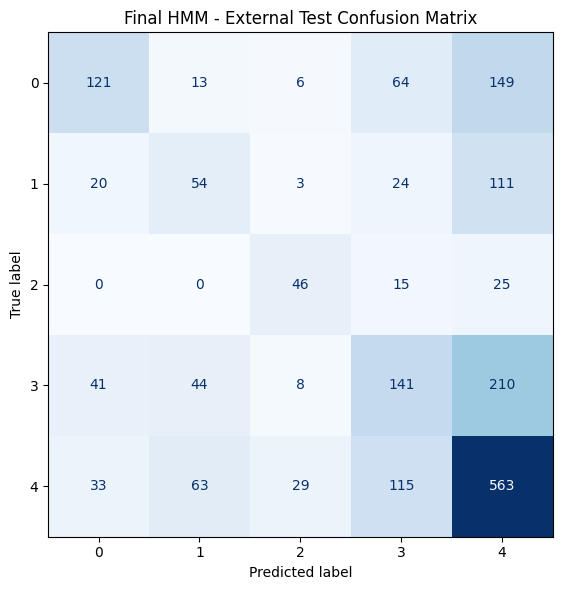

External evaluation logged successfully!
External evaluation run ID: 41f6b8f421fb46c5aacf43449afcbf38


In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

os.makedirs("/content/final_evaluation", exist_ok=True)

# Save predictions
predictions_df = external_test_data.copy()
predictions_df["actual_marks"] = actual_marks
predictions_df["actual_grade_band"] = actual_bands
predictions_df["predicted_marks"] = predicted_marks
predictions_df["predicted_grade_band"] = predicted_bands

prediction_path = "/content/final_evaluation/external_predictions.csv"
predictions_df.to_csv(prediction_path, index=False)

# Save classification report
report = classification_report(
    actual_bands,
    predicted_bands,
    labels=[0, 1, 2, 3, 4],
    output_dict=True,
    zero_division=0
)

report_path = "/content/final_evaluation/classification_report.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

# Save confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        actual_bands, predicted_bands, labels=[0, 1, 2, 3, 4]
    ),
    display_labels=[0, 1, 2, 3, 4]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Final HMM - External Test Confusion Matrix")
fig.tight_layout()

confusion_path = "/content/final_evaluation/confusion_matrix.png"
fig.savefig(confusion_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# Log final external evaluation
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
mlflow.set_experiment("HMM_Hyperparameter_Optimization")

with mlflow.start_run(run_name="Final_External_Test_Evaluation"):

    mlflow.log_params({
        "n_components": BEST_STATES,
        "n_iter": BEST_ITERATIONS,
        "smoothing_prior": BEST_PRIOR,
        "external_test_records": len(external_test_data)
    })

    mlflow.log_metrics({
        f"external_test_{key}": value
        for key, value in external_metrics.items()
    })

    mlflow.set_tags({
        "evaluation_type": "Independent External Test",
        "training_performed": "False",
        "selected_configuration": "BEST_HMM_CONFIG",
        "final_model_run_id": final_run_id,
        "selection_run_id": best_run.info.run_id
    })

    mlflow.log_artifact(prediction_path, artifact_path="external_evaluation")
    mlflow.log_artifact(report_path, artifact_path="external_evaluation")
    mlflow.log_artifact(confusion_path, artifact_path="external_evaluation")

    external_run_id = mlflow.active_run().info.run_id

print("External evaluation logged successfully!")
print("External evaluation run ID:", external_run_id)

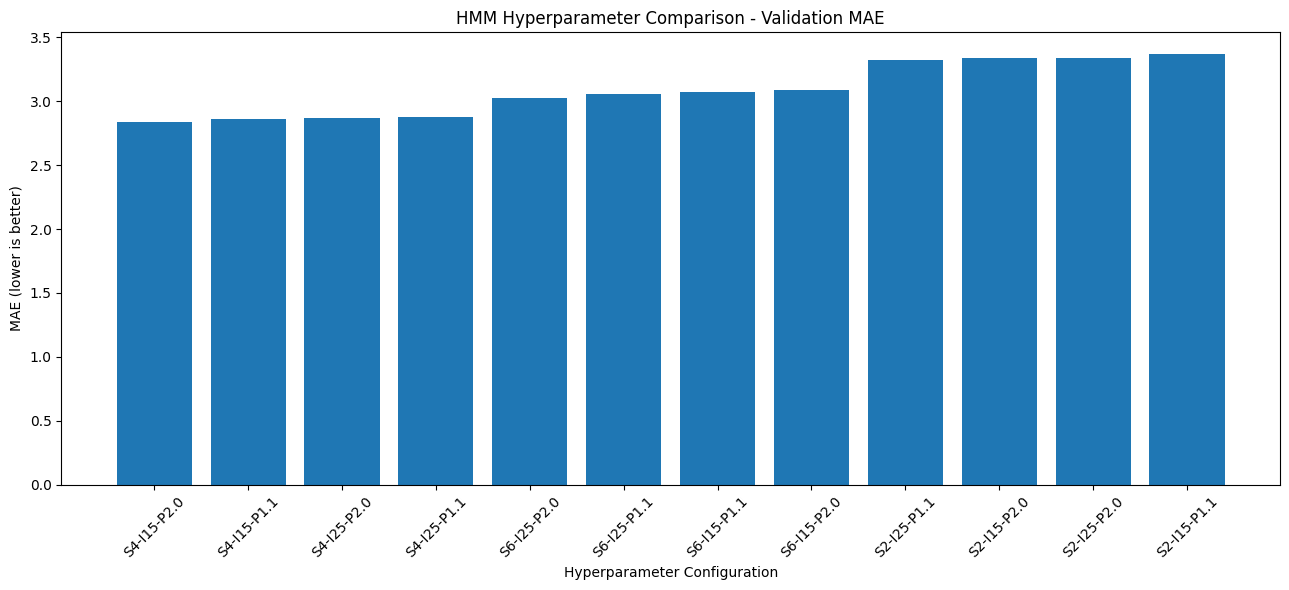

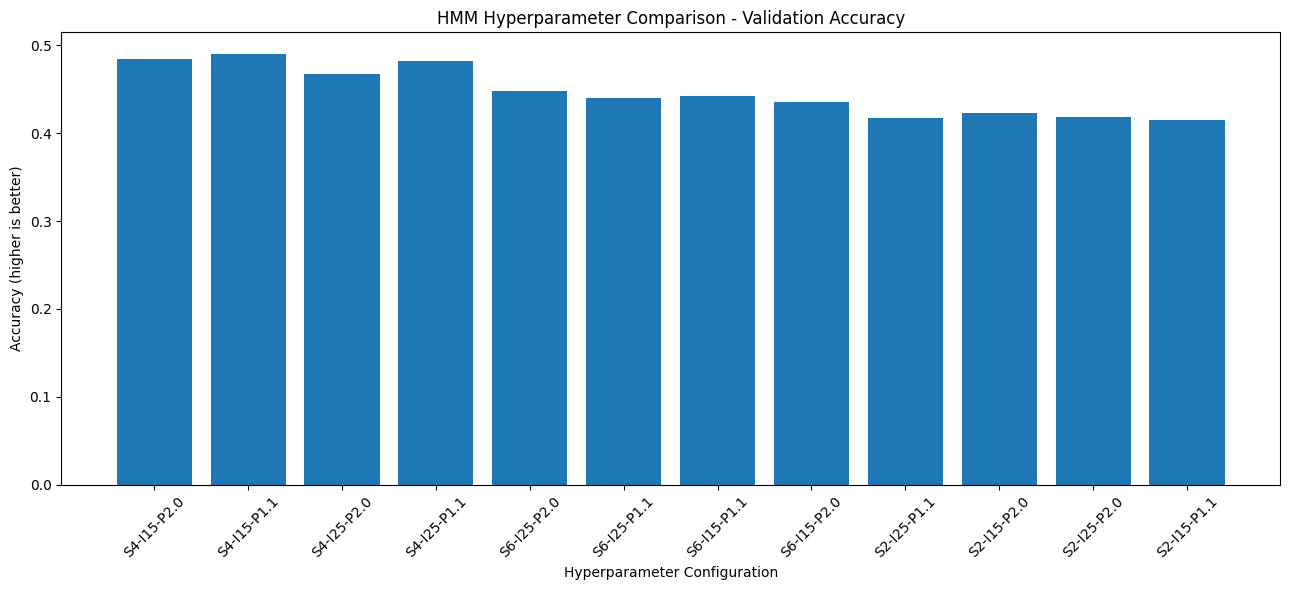

HYPERPARAMETER COMPARISON LOGGED!
Total configurations: 12
Best configuration: HMM_States4_Iter15_Prior2.0
Comparison Run ID: ada8153e083d499287503906b34980a5


,rank,run_name,n_components,n_iter,smoothing_prior,accuracy,mae,rmse,qwk,macro_f1,weighted_f1,training_seconds,is_best
0,1,HMM_States4_Iter15_Prior2.0,4,15,2.0,0.4843,2.8347,3.5779,0.2807,0.4422,0.4725,39.8303,True
1,2,HMM_States4_Iter15_Prior1.1,4,15,1.1,0.4903,2.8629,3.6613,0.3177,0.4523,0.4851,36.8955,False
2,3,HMM_States4_Iter25_Prior2.0,4,25,2.0,0.4672,2.8704,3.6091,0.2596,0.4327,0.4633,52.2640,False
3,4,HMM_States4_Iter25_Prior1.1,4,25,1.1,0.4820,2.8807,3.6776,0.3133,0.4530,0.4804,56.3188,False
4,5,HMM_States6_Iter25_Prior2.0,6,25,2.0,0.4480,3.0244,3.7871,0.2498,0.4304,0.4524,60.2473,False
5,6,HMM_States6_Iter25_Prior1.1,6,25,1.1,0.4404,3.0563,3.8548,0.2375,0.4301,0.4483,60.4183,False
6,7,HMM_States6_Iter15_Prior1.1,6,15,1.1,0.4418,3.0757,3.8827,0.2481,0.4307,0.4487,38.6560,False
7,8,HMM_States6_Iter15_Prior2.0,6,15,2.0,0.4352,3.0909,3.8732,0.2449,0.4245,0.4381,38.3185,False
8,9,HMM_States2_Iter25_Prior1.1,2,25,1.1,0.4170,3.3212,4.1418,0.1994,0.4209,0.4149,49.9516,False
9,10,HMM_States2_Iter15_Prior2.0,2,15,2.0,0.4233,3.3399,4.1255,0.2118,0.4279,0.4221,34.2909,False


In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import mlflow

os.makedirs("/content/hyperparameter_comparison", exist_ok=True)

# Sort all configurations by validation MAE
comparison_df = results_df.sort_values(
    ["mae", "qwk"],
    ascending=[True, False]
).reset_index(drop=True)

comparison_df.insert(
    0, "rank", range(1, len(comparison_df) + 1)
)

comparison_df["is_best"] = comparison_df["rank"] == 1

# Save comparison table
csv_path = "/content/hyperparameter_comparison/all_configurations.csv"
comparison_df.to_csv(csv_path, index=False)

# Plot 1: MAE comparison
fig, ax = plt.subplots(figsize=(13, 6))

labels = [
    f"S{s}-I{i}-P{p}"
    for s, i, p in zip(
        comparison_df["n_components"],
        comparison_df["n_iter"],
        comparison_df["smoothing_prior"]
    )
]

ax.bar(labels, comparison_df["mae"])
ax.set_title("HMM Hyperparameter Comparison - Validation MAE")
ax.set_xlabel("Hyperparameter Configuration")
ax.set_ylabel("MAE (lower is better)")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

mae_plot = "/content/hyperparameter_comparison/mae_comparison.png"
fig.savefig(mae_plot, dpi=150)
plt.show()
plt.close(fig)

# Plot 2: Accuracy comparison
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(labels, comparison_df["accuracy"])
ax.set_title("HMM Hyperparameter Comparison - Validation Accuracy")
ax.set_xlabel("Hyperparameter Configuration")
ax.set_ylabel("Accuracy (higher is better)")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

accuracy_plot = "/content/hyperparameter_comparison/accuracy_comparison.png"
fig.savefig(accuracy_plot, dpi=150)
plt.show()
plt.close(fig)

# Log a dedicated comparison run
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
mlflow.set_experiment("HMM_Hyperparameter_Optimization")

with mlflow.start_run(run_name="HMM_Hyperparameter_Comparison"):

    mlflow.set_tags({
        "run_type": "Hyperparameter Comparison",
        "selection_metric": "Validation MAE",
        "best_configuration": "HMM_States4_Iter15_Prior2.0"
    })

    mlflow.log_metric("total_configurations", len(comparison_df))

    mlflow.log_artifact(csv_path, artifact_path="comparison")
    mlflow.log_artifact(mae_plot, artifact_path="comparison")
    mlflow.log_artifact(accuracy_plot, artifact_path="comparison")

    comparison_run_id = mlflow.active_run().info.run_id

print("HYPERPARAMETER COMPARISON LOGGED!")
print("Total configurations:", len(comparison_df))
print("Best configuration:", comparison_df.iloc[0]["run_name"])
print("Comparison Run ID:", comparison_run_id)

display(comparison_df.round(4))

In [ ]:
import os
import zipfile

DB_PATH = "/content/hmm_hyperparameter_tuning.db"
MLRUNS_DIR = "/content/mlruns"

zip_path = "/content/hmm_mlflow_export.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    zipf.write(
        DB_PATH,
        arcname="hmm_hyperparameter_tuning.db"
    )

    for root, dirs, files_list in os.walk(MLRUNS_DIR):
        for file in files_list:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, "/content")
            zipf.write(file_path, arcname)

print("Corrected export created!")
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))
print("Artifacts included:", sum(len(f) for _, _, f in os.walk(MLRUNS_DIR)))

Corrected export created!
ZIP size (MB): 0.53
Artifacts included: 21


In [ ]:
from google.colab import files
files.download("/content/hmm_mlflow_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient

# Sort configurations by validation MAE
plot_df = comparison_df.sort_values(
    "mae", ascending=True
).copy()

labels = [
    f"States={s}, Iter={i}, Prior={p}"
    for s, i, p in zip(
        plot_df["n_components"],
        plot_df["n_iter"],
        plot_df["smoothing_prior"]
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

colors = [
    "green" if rank == 1 else "steelblue"
    for rank in plot_df["rank"]
]

bars = ax.barh(labels, plot_df["mae"], color=colors)

ax.invert_yaxis()
ax.set_title("HMM Hyperparameter Ranking - Validation MAE")
ax.set_xlabel("Mean Absolute Error (Lower is Better)")
ax.set_ylabel("Hyperparameter Configuration")

for bar, accuracy in zip(bars, plot_df["accuracy"]):
    ax.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"Accuracy: {accuracy:.2%}",
        va="center",
        fontsize=8
    )

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="green", label="Best Configuration"),
        plt.Rectangle((0, 0), 1, 1, color="steelblue", label="Other Configurations")
    ],
    loc="lower right"
)

plt.tight_layout()

plot_path = "/content/hyperparameter_comparison/best_configuration_ranking.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

# Add plot to the existing comparison run
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

client = MlflowClient()

client.log_artifact(
    run_id="ada8153e083d499287503906b34980a5",
    local_path=plot_path,
    artifact_path="comparison"
)

print("Ranking plot saved and logged to MLflow!")

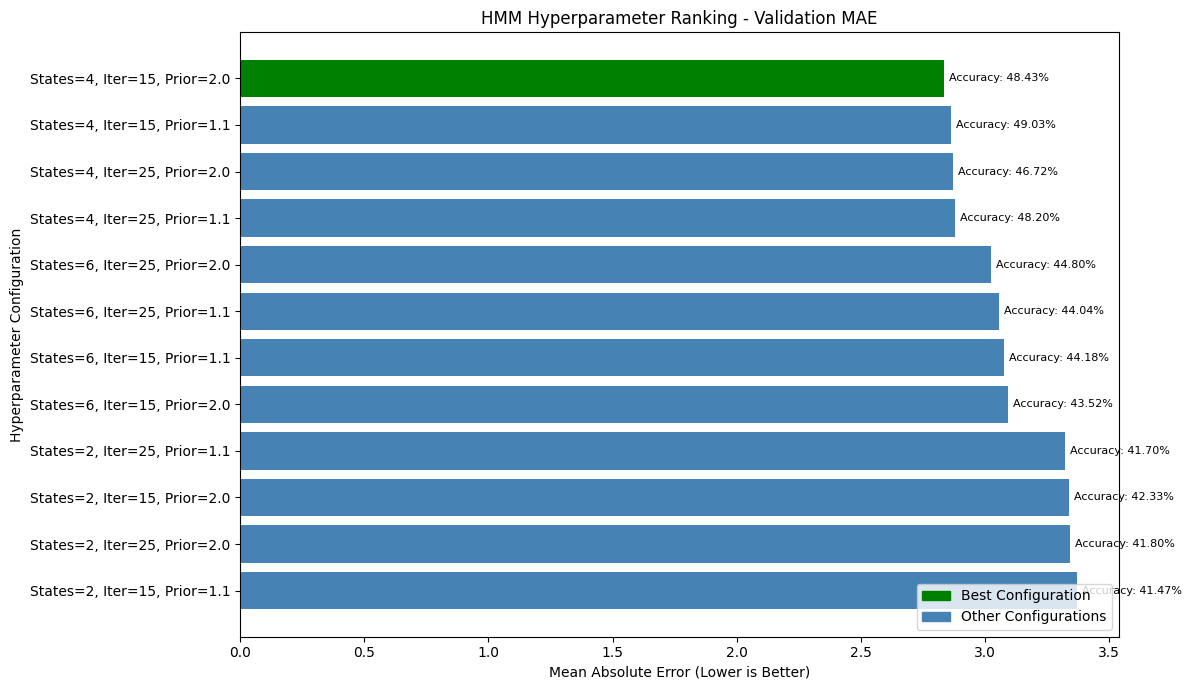

Ranking plot saved and logged to MLflow!


In [ ]:
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient

# Sort configurations by validation MAE
plot_df = comparison_df.sort_values(
    "mae", ascending=True
).copy()

labels = [
    f"States={s}, Iter={i}, Prior={p}"
    for s, i, p in zip(
        plot_df["n_components"],
        plot_df["n_iter"],
        plot_df["smoothing_prior"]
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

colors = [
    "green" if rank == 1 else "steelblue"
    for rank in plot_df["rank"]
]

bars = ax.barh(labels, plot_df["mae"], color=colors)

ax.invert_yaxis()
ax.set_title("HMM Hyperparameter Ranking - Validation MAE")
ax.set_xlabel("Mean Absolute Error (Lower is Better)")
ax.set_ylabel("Hyperparameter Configuration")

for bar, accuracy in zip(bars, plot_df["accuracy"]):
    ax.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"Accuracy: {accuracy:.2%}",
        va="center",
        fontsize=8
    )

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="green", label="Best Configuration"),
        plt.Rectangle((0, 0), 1, 1, color="steelblue", label="Other Configurations")
    ],
    loc="lower right"
)

plt.tight_layout()

plot_path = "/content/hyperparameter_comparison/best_configuration_ranking.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

# Add plot to the existing comparison run
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

client = MlflowClient()

client.log_artifact(
    run_id="ada8153e083d499287503906b34980a5",
    local_path=plot_path,
    artifact_path="comparison"
)

print("Ranking plot saved and logged to MLflow!")

In [ ]:
import os
import zipfile

zip_path = "/content/hmm_mlflow_export.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(
        MLFLOW_DB,
        arcname="hmm_hyperparameter_tuning.db"
    )

    for root, dirs, files_list in os.walk("/content/mlruns"):
        for file in files_list:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, "/content")
            zipf.write(file_path, arcname=arcname)

print("Updated ZIP created!")

Updated ZIP created!


In [ ]:
from google.colab import files
files.download("/content/hmm_mlflow_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>